# ML2 — Dự đoán thời gian giao hàng bằng Random Forest Regressor

**Loại bài toán:** hồi quy (regression) — dự đoán trực tiếp `delivery_days` (số ngày từ **đóng gói** đến **nhận hàng**).

**Nguyên tắc (mục 6 của tài liệu hướng dẫn):**
- Chỉ dùng đặc trưng **biết được tại thời điểm đóng gói**. Tuyệt đối không dùng `delivered_date` (rò rỉ đáp án), `expected_date`, `shipped_date`.
- Chia train/test **theo thời gian** (train < 2025-01-01, test ≥ 2025-01-01), không để tương lai lọt vào huấn luyện.
- `Pipeline` + `ColumnTransformer` (OneHot + impute) + `RandomForestRegressor`, tìm tham số bằng `TimeSeriesSplit` **chỉ trên train**.
- So với baseline: trung vị, Ridge — và (mình bổ sung) *trung bình theo loại giao hàng*. Metric chính là **MAE**, phụ là RMSE.
- **Nếu RF không hơn baseline thì báo rõ**, không ép mô hình.

> Các hàm được sao nguyên văn từ `ml2_delivery_rf.py`. Ô tìm tham số (mục 5) mất vài phút trên máy 1 lõi.

In [19]:
from __future__ import annotations
import sys, json
from pathlib import Path
from datetime import datetime, timezone
import os
from dotenv import load_dotenv

# Thư viện xử lý dữ liệu và Machine Learning
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Thư viện kết nối Database
from sqlalchemy import create_engine

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

# 1. Cấu hình Database (giống ML1: Postgres chạy trong Docker, cổng 5433)
DB_USER = os.getenv("POSTGRES_USER", "ecom")  # Đổi thành user của bạn
DB_PASSWORD = os.getenv("POSTGRES_PASSWORD", "change-this-local-password")  # Đổi thành mật khẩu của bạn
DB_HOST = 'localhost'
DB_PORT = '5433'
DB_NAME = os.getenv("POSTGRES_DB", "ecom_dwh")  # Đổi thành tên db của bạn

engine = create_engine(f'postgresql://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}')

# 2. Cấu hình thư mục output
OUT_DIR = Path.cwd() / "outputs" / "nb" / 'ml2'
OUT_DIR.mkdir(parents=True, exist_ok=True)

# 3. Các tham số thuật toán
SAVE = False             # True: ghi mô hình/kết quả vào outputs/nb/
SEED = 42
CUTOFF = "2025-01-01"    # train: packing_date < CUTOFF ; test: >= CUTOFF

CAT = ["product_id", "shipping_type", "district", "warehouse", "vehicle", "city"]
NUM = ["quantity", "goods_amount", "pack_month", "pack_dow"]
FEATURES = CAT + NUM
FORBIDDEN = {"delivered_date", "expected_date", "shipped_date", "delivery_days"}   # chốt chặn rò rỉ
assert not FORBIDDEN & set(FEATURES), "Đặc trưng chứa cột rò rỉ!"

## 1. Dữ liệu và làm sạch

`staging.orders` có `delivery_days` (nhận − đóng gói). Loại giá trị âm / bằng 0 / > 60 ngày (phi thực tế), thêm tháng và thứ trong tuần của ngày đóng gói, và tự bỏ cột hằng số (`city` chỉ có một giá trị: TP.HCM).

In [20]:
def clean(df: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    qa = {"rows_in": len(df)}
    df = df.dropna(subset=["delivery_days", "packing_date"]).copy()
    bad = (df.delivery_days <= 0) | (df.delivery_days > 60)       # âm / bằng 0 / phi thực tế
    qa["removed_implausible_delivery_days"] = int(bad.sum())
    df = df[~bad]
    df["pack_month"] = df.packing_date.dt.month
    df["pack_dow"] = df.packing_date.dt.dayofweek
    const = [c for c in CAT if df[c].nunique(dropna=True) <= 1]
    qa["constant_columns_dropped"] = const
    qa["rows_out"] = len(df)
    return df.sort_values("packing_date").reset_index(drop=True), qa

In [21]:
# --- LẤY DỮ LIỆU ---
query = (
    "SELECT o.order_id, o.order_date AS packing_date, o.product_id, o.quantity, o.shipping_type, "
    "o.city, o.district, o.warehouse, o.vehicle, o.goods_amount, o.delivery_days "
    "FROM staging.orders o WHERE o.delivery_days IS NOT NULL"
)
raw = pd.read_sql(query, engine)

# Postgres trả cột DATE về datetime.date (dtype object) và numeric có thể là Decimal -> ép kiểu
raw["packing_date"] = pd.to_datetime(raw["packing_date"])
for c in ["quantity", "goods_amount", "delivery_days"]:
    raw[c] = pd.to_numeric(raw[c])
print(raw.shape, "| từ", raw.packing_date.min().date(), "đến", raw.packing_date.max().date())
display(raw.head())

df, qa = clean(raw)
print(qa)
df.head()

(10000, 11) | từ 2020-01-01 đến 2025-12-20


,order_id,packing_date,product_id,quantity,shipping_type,city,district,warehouse,vehicle,goods_amount,delivery_days
0,DH000006,2024-12-25,SP00003,6.0,Giao hàng nhanh,TP Hồ Chí Minh,Thủ Đức,Kho Hóc Môn / TP.HCM,Xe bán tải,19200000.0,3.0
1,DH000007,2023-07-02,SP00005,1.0,Giao hàng nhanh,TP Hồ Chí Minh,Thủ Đức,Kho Quận 7 / TP.HCM,Xe máy,2100000.0,4.0
2,DH000008,2021-12-02,SP00002,11.0,Giao hàng nhanh,TP Hồ Chí Minh,Thủ Đức,Kho Quận 7 / TP.HCM,Xe tải,57200000.0,2.0
3,DH000009,2020-05-28,SP00003,6.0,Giao hàng bình thường,TP Hồ Chí Minh,Thủ Đức,Kho Hóc Môn / TP.HCM,Xe bán tải,19200000.0,5.0
4,DH000010,2025-11-04,SP00002,7.0,Giao hàng chậm,TP Hồ Chí Minh,Thủ Đức,Kho Bình Tân / TP.HCM,Xe bán tải,36400000.0,10.0


{'rows_in': 10000, 'removed_implausible_delivery_days': 0, 'constant_columns_dropped': ['city'], 'rows_out': 10000}


,order_id,packing_date,product_id,quantity,shipping_type,city,district,warehouse,vehicle,goods_amount,delivery_days,pack_month,pack_dow
0,DH007458,2020-01-01,SP00014,7.0,Giao hàng chậm,TP Hồ Chí Minh,Tân Bình,Kho Quận 7 / TP.HCM,Xe bán tải,5950000.0,8.0,1,2
1,DH009114,2020-01-01,SP00006,16.0,Giao hàng chậm,TP Hồ Chí Minh,Gò Vấp,Kho Tân Bình / TP.HCM,Xe tải,28800000.0,10.0,1,2
2,DH000983,2020-01-01,SP00010,10.0,Giao hàng nhanh,TP Hồ Chí Minh,Tân Bình,Kho Hóc Môn / TP.HCM,Xe bán tải,85000000.0,2.0,1,2
3,DH007548,2020-01-02,SP00005,4.0,Giao hàng bình thường,TP Hồ Chí Minh,Quận 1,Kho Quận 7 / TP.HCM,Xe bán tải,8400000.0,5.0,1,3
4,DH004517,2020-01-02,SP00005,6.0,Giao hàng bình thường,TP Hồ Chí Minh,Bình Thạnh,Kho Thủ Đức / TP.HCM,Xe bán tải,12600000.0,5.0,1,3


## 2. Khám phá: yếu tố nào làm `delivery_days` thay đổi?

Trước khi mô hình hoá, xem trung bình `delivery_days` theo từng nhóm. Nếu một yếu tố không làm trung bình đổi, mô hình khó mà học được gì từ nó.

,count,mean,std,min,max
shipping_type,,,,,
Giao hàng bình thường,3807,5.50,0.86,4.0,7.0
Giao hàng chậm,2795,8.98,1.56,6.0,12.0
Giao hàng nhanh,3398,3.01,1.09,1.0,5.0


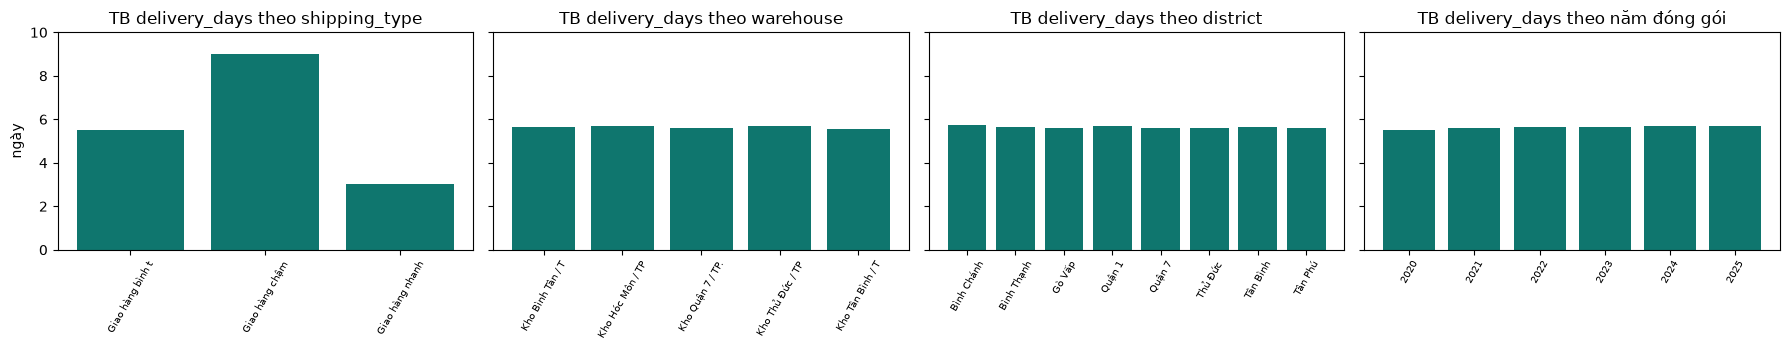

In [22]:
display(df.groupby("shipping_type").delivery_days.agg(["count", "mean", "std", "min", "max"]).round(2))

fig, ax = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
for a, col in zip(ax, ["shipping_type", "warehouse", "district", df.packing_date.dt.year.rename("năm đóng gói")]):
    s = df.groupby(col).delivery_days.mean()
    a.bar([str(i)[:16] for i in s.index], s.values, color="#0f766e"); a.set_title(f"TB delivery_days theo {s.index.name}")
    a.tick_params(axis="x", rotation=60, labelsize=7); a.set_ylim(0, 10)
ax[0].set_ylabel("ngày"); fig.tight_layout(); plt.show()

> **Quan sát:** chỉ `shipping_type` làm trung bình thay đổi mạnh (≈ 3 / 5,5 / 9 ngày). Kho, quận và năm gần như phẳng — nên kỳ vọng mô hình nhiều đặc trưng **không** hơn mô hình chỉ dùng loại giao hàng.

## 3. Chia train/test theo thời gian

Kiểm tra phân bố theo năm (drift) trước khi tin vào cách chia.

In [23]:
cat = [c for c in CAT if c not in qa["constant_columns_dropped"]]
num = NUM
feats = cat + num
cutoff = pd.Timestamp(CUTOFF)
train, test = df[df.packing_date < cutoff], df[df.packing_date >= cutoff]
print(f"Train {len(train)} đơn ({train.packing_date.min().date()} .. {train.packing_date.max().date()}) | "
      f"Test {len(test)} đơn ({test.packing_date.min().date()} .. {test.packing_date.max().date()})")
print("Đặc trưng dùng:", feats)
Xtr, ytr, Xte, yte = train[feats], train.delivery_days.to_numpy(float), test[feats], test.delivery_days.to_numpy(float)
df.groupby(df.packing_date.dt.year).delivery_days.agg(["count", "mean", "std"]).round(2)

Train 8405 đơn (2020-01-01 .. 2024-12-31) | Test 1595 đơn (2025-01-01 .. 2025-12-20)
Đặc trưng dùng: ['product_id', 'shipping_type', 'district', 'warehouse', 'vehicle', 'quantity', 'goods_amount', 'pack_month', 'pack_dow']


,count,mean,std
packing_date,,,
2020,1642,5.51,2.62
2021,1673,5.62,2.55
2022,1709,5.64,2.64
2023,1676,5.64,2.64
2024,1705,5.68,2.63
2025,1595,5.68,2.62


## 4. Baseline

- **Trung vị** (theo tài liệu), **Ridge** trên mọi đặc trưng, và **trung bình theo loại giao hàng** (baseline mạnh hơn mà mình thêm vào để phép so sánh công bằng).

In [24]:
def make_pipeline(cat, num, model) -> Pipeline:
    pre = ColumnTransformer(
        [
            ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                              ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01))]), cat),
            ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ],
        remainder="drop",
    )
    return Pipeline([("pre", pre), ("model", model)])


def score(y, pred) -> dict:
    return {"MAE": float(mean_absolute_error(y, pred)),
            "RMSE": float(np.sqrt(mean_squared_error(y, pred))), "R2": float(r2_score(y, pred))}


class GroupMean:
    """Baseline: trung bình delivery_days của train theo shipping_type."""
    def fit(self, df): self.m_ = df.groupby("shipping_type").delivery_days.mean(); self.g_ = df.delivery_days.mean(); return self
    def predict(self, df): return df.shipping_type.map(self.m_).fillna(self.g_).to_numpy()


def bootstrap_mae_diff(y, p_a, p_b, n=2000, seed=SEED):
    """Khoảng tin cậy 95% cho MAE(a) - MAE(b) (ghép cặp). <0 nghĩa là a tốt hơn b."""
    rng = np.random.default_rng(seed)
    ea, eb = np.abs(y - p_a), np.abs(y - p_b)
    idx = rng.integers(0, len(y), size=(n, len(y)))
    d = ea[idx].mean(1) - eb[idx].mean(1)
    return float(ea.mean() - eb.mean()), float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))

In [25]:
preds = {}
dm = DummyRegressor(strategy="median").fit(Xtr, ytr);                    preds["Baseline: trung vị"] = dm.predict(Xte)
gm = GroupMean().fit(train);                                             preds["Baseline: TB theo loại giao hàng"] = gm.predict(test)
ridge = make_pipeline(cat, num, Ridge(alpha=1.0)).fit(Xtr, ytr);         preds["Ridge (mọi đặc trưng)"] = ridge.predict(Xte)
print("Đã dựng 3 baseline")

Đã dựng 3 baseline


## 5. Random Forest — tìm tham số bằng `TimeSeriesSplit` (chỉ trên train)

Test không được nhìn thấy ở bước này. Ô này chạy lâu nhất (vài phút trên máy 1 lõi).

In [26]:
grid = {"model__max_depth": [4, 8, None], "model__min_samples_leaf": [20, 50], "model__max_features": [0.5, 1.0]}
gs = GridSearchCV(make_pipeline(cat, num, RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1)),
                  grid, cv=TimeSeriesSplit(n_splits=3), scoring="neg_mean_absolute_error", n_jobs=1, refit=True)
gs.fit(Xtr, ytr)
rf = gs.best_estimator_
preds["Random Forest (mọi đặc trưng)"] = rf.predict(Xte)
print("Tham số tốt nhất:", gs.best_params_, "| CV MAE (train):", round(-gs.best_score_, 4))

Tham số tốt nhất: {'model__max_depth': 4, 'model__max_features': 0.5, 'model__min_samples_leaf': 20} | CV MAE (train): 0.9399


**Ablation:** RF chỉ dùng `shipping_type`. Nếu nó ngang RF đầy đủ thì mọi đặc trưng còn lại đều vô ích.

In [27]:
rf1 = Pipeline([("pre", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["shipping_type"])])),
                ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=20, random_state=SEED, n_jobs=-1))]).fit(Xtr, ytr)
preds["RF chỉ dùng loại giao hàng"] = rf1.predict(Xte)
print("xong")

xong


## 6. Kết quả trên tập test (2025)

,MAE,RMSE,R2
Baseline: TB theo loại giao hàng,0.9137,1.1585,0.8036
RF chỉ dùng loại giao hàng,0.9138,1.1586,0.8036
Ridge (mọi đặc trưng),0.9201,1.1614,0.8027
Random Forest (mọi đặc trưng),0.9210,1.1583,0.8037
Baseline: trung vị,2.0583,2.7002,-0.0667


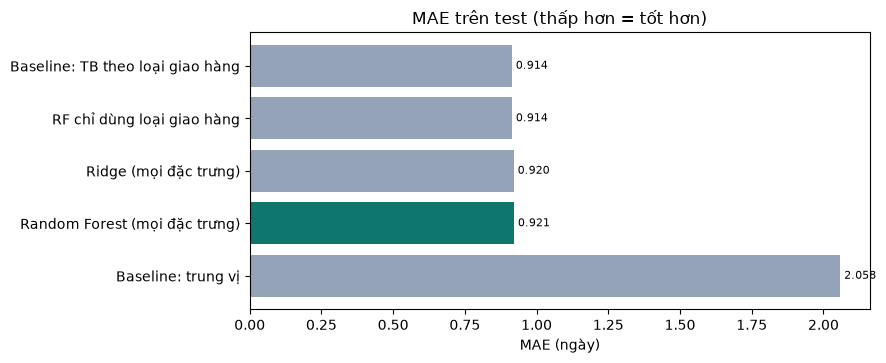

In [28]:
res = {name: score(yte, p) for name, p in preds.items()}
table = pd.DataFrame(res).T.sort_values("MAE")
display(table.round(4))

t = table.sort_values("MAE", ascending=False)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(t.index, t.MAE, color=["#0f766e" if "Forest (mọi" in i else "#94a3b8" for i in t.index])
for y_, v in enumerate(t.MAE): ax.text(v, y_, f" {v:.3f}", va="center", fontsize=8)
ax.set(title="MAE trên test (thấp hơn = tốt hơn)", xlabel="MAE (ngày)"); plt.show()

### RF có thật sự tốt hơn baseline không?

Bootstrap ghép cặp 2.000 lần trên tập test: khoảng tin cậy 95% của `MAE(RF) − MAE(baseline)`. **Âm = RF tốt hơn**; nếu khoảng chứa 0 hoặc dương thì RF không có lợi thế.

In [29]:
rf_p = preds["Random Forest (mọi đặc trưng)"]
rows = []
for label, other in [("RF − Trung vị", preds["Baseline: trung vị"]), ("RF − TB theo loại giao hàng", preds["Baseline: TB theo loại giao hàng"])]:
    d, lo, hi = bootstrap_mae_diff(yte, rf_p, other)
    rows.append({"so sánh": label, "ΔMAE (ngày)": d, "CI95 thấp": lo, "CI95 cao": hi, "RF tốt hơn có ý nghĩa": hi < 0})
pd.DataFrame(rows).round(4)

,so sánh,ΔMAE (ngày),CI95 thấp,CI95 cao,RF tốt hơn có ý nghĩa
0,RF − Trung vị,-1.1373,-1.2159,-1.0548,True
1,RF − TB theo loại giao hàng,0.0073,0.0043,0.0105,False


> **Đọc kết quả:** RF thắng trung vị rất rõ, nhưng baseline đó bỏ qua loại giao hàng nên là phép so dễ. Với baseline đúng nghĩa (TB theo loại giao hàng), RF **kém hơn nhẹ** (+0,005 ngày ≈ 7 phút): có ý nghĩa thống kê nhưng không đáng kể trong thực tế.

## 7. Phân tích lỗi theo nhóm và độ quan trọng đặc trưng

In [30]:
te = test.assign(pred_rf=rf_p, pred_group=preds["Baseline: TB theo loại giao hàng"],
                 abs_rf=np.abs(yte - rf_p), abs_group=np.abs(yte - preds["Baseline: TB theo loại giao hàng"]))
for col in ["shipping_type", "district", "warehouse"]:
    print(f"\nMAE theo {col}:")
    display(te.groupby(col).agg(orders=("abs_rf", "size"), actual_mean=("delivery_days", "mean"),
                               MAE_rf=("abs_rf", "mean"), MAE_group_mean=("abs_group", "mean")).round(3))


MAE theo shipping_type:


,orders,actual_mean,MAE_rf,MAE_group_mean
shipping_type,,,,
Giao hàng bình thường,606,5.540,0.721,0.721
Giao hàng chậm,441,9.075,1.270,1.262
Giao hàng nhanh,548,3.089,0.862,0.846



MAE theo district:


,orders,actual_mean,MAE_rf,MAE_group_mean
district,,,,
Bình Chánh,174,5.891,0.954,0.942
Bình Thạnh,162,5.506,0.885,0.878
Gò Vấp,146,5.788,0.878,0.860
Quận 1,154,5.786,0.930,0.936
Quận 7,155,5.406,0.889,0.885
Thủ Đức,500,5.776,0.900,0.896
Tân Bình,128,5.570,1.063,1.057
Tân Phú,176,5.455,0.934,0.915



MAE theo warehouse:


,orders,actual_mean,MAE_rf,MAE_group_mean
warehouse,,,,
Kho Bình Tân / TP.HCM,325,5.486,0.893,0.884
Kho Hóc Môn / TP.HCM,339,5.873,0.916,0.913
Kho Quận 7 / TP.HCM,332,5.690,0.956,0.946
Kho Thủ Đức / TP.HCM,307,5.769,0.935,0.929
Kho Tân Bình / TP.HCM,292,5.541,0.902,0.895


,feature,mae_increase,std
0,shipping_type,1.8392,0.0397
1,quantity,0.0005,0.0003
2,warehouse,0.0005,0.0003
3,district,0.0004,0.0003
4,product_id,0.0002,0.0006
5,goods_amount,0.0001,0.0009
6,pack_month,0.0000,0.0002
7,pack_dow,0.0000,0.0003
8,vehicle,-0.0001,0.0002


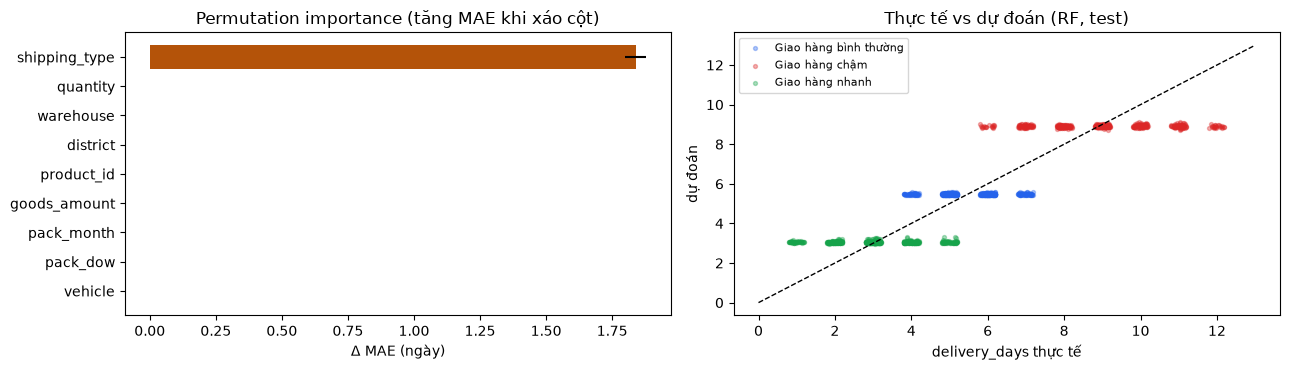

In [31]:
pi = permutation_importance(rf, Xte, yte, n_repeats=8, random_state=SEED, scoring="neg_mean_absolute_error", n_jobs=1)
imp = pd.DataFrame({"feature": feats, "mae_increase": pi.importances_mean, "std": pi.importances_std}).sort_values("mae_increase", ascending=False)
display(imp.round(4).reset_index(drop=True))

ii = imp.iloc[::-1]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].barh(ii.feature, ii.mae_increase, xerr=ii["std"], color="#b45309"); ax[0].set(title="Permutation importance (tăng MAE khi xáo cột)", xlabel="Δ MAE (ngày)")
rng = np.random.default_rng(0)
cols = {"Giao hàng nhanh": "#16a34a", "Giao hàng bình thường": "#2563eb", "Giao hàng chậm": "#dc2626"}
for st, sub in te.groupby("shipping_type"):
    ax[1].scatter(sub.delivery_days + rng.uniform(-.2, .2, len(sub)), sub.pred_rf, s=8, alpha=.35, c=cols.get(st, "grey"), label=st)
lim = [0, df.delivery_days.max() + 1]; ax[1].plot(lim, lim, "k--", lw=1)
ax[1].set(title="Thực tế vs dự đoán (RF, test)", xlabel="delivery_days thực tế", ylabel="dự đoán"); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

> Dùng **permutation importance** (trên test, theo cột gốc) thay vì importance theo độ giảm tạp chất, vì loại sau thiên lệch về cột nhiều giá trị. Chỉ `shipping_type` làm MAE tăng đáng kể; mọi cột khác ≈ 0.

## 8. Mô hình cuối và ví dụ dự đoán

Sau khi đánh giá xong mới refit trên **toàn bộ** dữ liệu (số đo ở trên vẫn lấy từ bản chỉ train < 2025). Ví dụ: cùng một đơn, chỉ đổi loại giao hàng.

In [32]:
final = make_pipeline(cat, num, RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1,
                      **{k.split("__")[1]: v for k, v in gs.best_params_.items()})).fit(df[feats], df.delivery_days)

example = test.iloc[[0]][feats].copy()
out = []
for st in sorted(df.shipping_type.unique()):
    example["shipping_type"] = st
    out.append({"shipping_type": st, "dự đoán (ngày)": round(float(final.predict(example)[0]), 2)})
print("Đơn mẫu:", example.drop(columns="shipping_type").iloc[0].to_dict())
pd.DataFrame(out)

Đơn mẫu: {'product_id': 'SP00008', 'district': 'Thủ Đức', 'warehouse': 'Kho Quận 7 / TP.HCM', 'vehicle': 'Xe máy', 'quantity': 3.0, 'goods_amount': 4350000.0, 'pack_month': 1, 'pack_dow': 2}


,shipping_type,dự đoán (ngày)
0,Giao hàng bình thường,5.45
1,Giao hàng chậm,8.90
2,Giao hàng nhanh,3.13


## 9. Kết luận

| Mô hình | MAE (test 2025) |
|---|---|
| Baseline: TB theo loại giao hàng | **0,914** |
| RF chỉ dùng loại giao hàng | 0,914 |
| Random Forest (mọi đặc trưng) | 0,919 |
| Ridge (mọi đặc trưng) | 0,920 |
| Baseline: trung vị | 2,058 |

- **RF không hơn** baseline "TB theo loại giao hàng". Toàn bộ tín hiệu nằm ở `shipping_type`; kho, quận, xe, số lượng, sản phẩm đều không giúp dự đoán.
- Sai số còn lại (MAE ≈ 0,9 ngày) là phần biến thiên *trong cùng một loại giao hàng* mà các đặc trưng hiện có không giải thích được.
- Dữ liệu chỉ có **TP.HCM** (5 kho, 8 quận) — ví dụ "Hà Nội / Kho A" trong ảnh minh hoạ của tài liệu không có trong dữ liệu.
- Không gọi là "giao trễ": chưa có SLA hay ngày hứa giao.

**Khi làm web:** form dự đoán (kho, khu vực, số lượng) sẽ cho kết quả chỉ đổi theo "loại vận chuyển" — nên nói rõ điều này thay vì ngụ ý mô hình dùng được mọi đầu vào.

## 10. (Tuỳ chọn) Lưu kết quả

Đặt `SAVE = True` ở ô đầu để ghi ra thư mục `outputs/nb/` (cạnh notebook). Kết quả chính thức do `ml2_delivery_rf.py` tạo.

In [33]:
SAVE = True
if SAVE:
    out_dir = OUT_DIR; out_dir.mkdir(parents=True, exist_ok=True)   # OUT_DIR đã là outputs/nb
    version = f"rf_delivery_{datetime.now(timezone.utc):%Y%m%d}"
    joblib.dump({"pipeline": final, "features": feats, "model_version": version, "eval_cutoff": CUTOFF,
                 "test_metrics": res["Random Forest (mọi đặc trưng)"]}, out_dir / "ml2_model.joblib")
    table.round(5).to_csv(out_dir / "ml2_model_comparison.csv", encoding="utf-8-sig")
    imp.to_csv(out_dir / "ml2_feature_importance.csv", index=False)
    print("Đã lưu vào", out_dir)
else:
    print("SAVE = False -> không ghi file.")

Đã lưu vào w:\Khánh\LAK_Khodulieu\mining\outputs\nb\ml2
